# Customer Segmentation Analysis

## Oasis Infobyte Data Analytics Internship — Level 1 Task 2

### Objective

The objective of this project is to apply customer segmentation techniques to an online retail dataset. Customers will be grouped according to their purchasing behaviour using Recency, Frequency, and Monetary (RFM) features and the K-Means clustering algorithm.

The resulting customer segments will be profiled and used to develop targeted marketing recommendations.

### Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Load and Inspect the Dataset

In [22]:
data_path = Path("../data/Online Retail.xlsx")

df = pd.read_excel(data_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [23]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset information:")
df.info()

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

Missing values:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Duplicate rows: 5268

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


### Initial Observations

The dataset contains online retail transactions rather than one row per customer. Therefore, the transaction records must be aggregated into customer-level features before clustering.

Customer IDs and invoice dates are particularly important because they allow us to measure purchasing frequency and recency.

## 2. Data Cleaning

In [24]:
df_clean = df.copy()

# Convert dates to datetime
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# Remove records without a customer ID or valid invoice date
df_clean = df_clean.dropna(
    subset=["CustomerID", "InvoiceDate"]
)

# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep positive quantities and prices for the purchasing analysis
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# Standardize customer ID representation
df_clean["CustomerID"] = (
    df_clean["CustomerID"].astype(int).astype(str)
)

# Calculate transaction-line revenue
df_clean["TotalPrice"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Customers remaining:", df_clean["CustomerID"].nunique())

display(df_clean.head())

Original rows: 541909
Cleaned rows: 397884
Customers remaining: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


### Cleaning Observations

The original dataset contained 541,909 transaction records. After removing records with missing customer IDs or invalid dates, cancellation invoices, and transactions with non-positive quantities or unit prices, 397,884 records remained for analysis. The cleaned dataset contained 4,338 unique customers.

Revenue was calculated by multiplying quantity by unit price. These cleaning steps focused the analysis on completed, positive-value purchases suitable for customer segmentation.

## 3. Customer-Level Feature Engineering: RFM Analysis

In [25]:
snapshot_date = (
    df_clean["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

rfm = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda dates:
             (snapshot_date - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

print("Customer-level dataset shape:", rfm.shape)
display(rfm.head())

Customer-level dataset shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,325,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,18,1,1757.55
4,12350,310,1,334.40


### Average Purchase Value

In [26]:
rfm["Avg_Purchase_Value"] = (
    rfm["Monetary"] / rfm["Frequency"]
)

display(
    rfm[[
        "Recency",
        "Frequency",
        "Monetary",
        "Avg_Purchase_Value"
    ]].describe().round(2)
)

,Recency,Frequency,Monetary,Avg_Purchase_Value
count,4338.00,4338.00,4338.00,4338.00
mean,92.06,4.27,2054.27,419.17
std,100.01,7.70,8989.23,1796.54
min,0.00,1.00,3.75,3.45
25%,17.00,1.00,307.41,178.62
50%,50.00,2.00,674.48,293.90
75%,141.75,5.00,1661.74,430.11
max,373.00,209.00,280206.02,84236.25


### Descriptive Statistics Observations

- **Recency:** The average recency was 92.06 days, while the median was 50 days. This indicates that customers' time since their last purchase varied considerably.
- **Purchase Frequency:** Customers made an average of 4.27 purchases (invoices), while the median was 2. This suggests that most customers purchased relatively infrequently, while some customers made many more purchases.
- **Monetary Value:** Average historical spending per customer was £2,054.27, compared with a median of £674.48. The difference suggests that a smaller number of high-spending customers increased the average.
- **Average Purchase Value:** The average customer-level purchase value was £419.17 per invoice, while the median was £293.90. The difference indicates variation in spending per invoice across customers.
- **Overall Finding:** The large differences between the means and medians, together with the high maximum values, indicate that customer purchasing behaviour is uneven. RFM analysis can help identify these differences and group customers with similar purchasing patterns.

In [27]:
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.06,4.27,2054.27
std,100.01,7.70,8989.23
min,0.00,1.00,3.75
25%,17.00,1.00,307.41
50%,50.00,2.00,674.48
75%,141.75,5.00,1661.74
max,373.00,209.00,280206.02


In [28]:
rfm_summary = rfm[["Recency", "Frequency", "Monetary"]].agg(
    ["mean", "median", "std", "min", "max"]
).T

display(rfm_summary.round(2))

,mean,median,std,min,max
Recency,92.06,50.00,100.01,0.00,373.00
Frequency,4.27,2.00,7.70,1.00,209.00
Monetary,2054.27,674.48,8989.23,3.75,280206.02


### RFM Observations

The RFM table represents each customer as one row instead of treating each transaction as a separate customer.

Recency measures how recently a customer purchased, Frequency measures the number of distinct invoices, and Monetary measures total recorded spending. These features provide different perspectives on customer behaviour and will be used to identify customer segments.

## 4. Explore Customer Behaviour

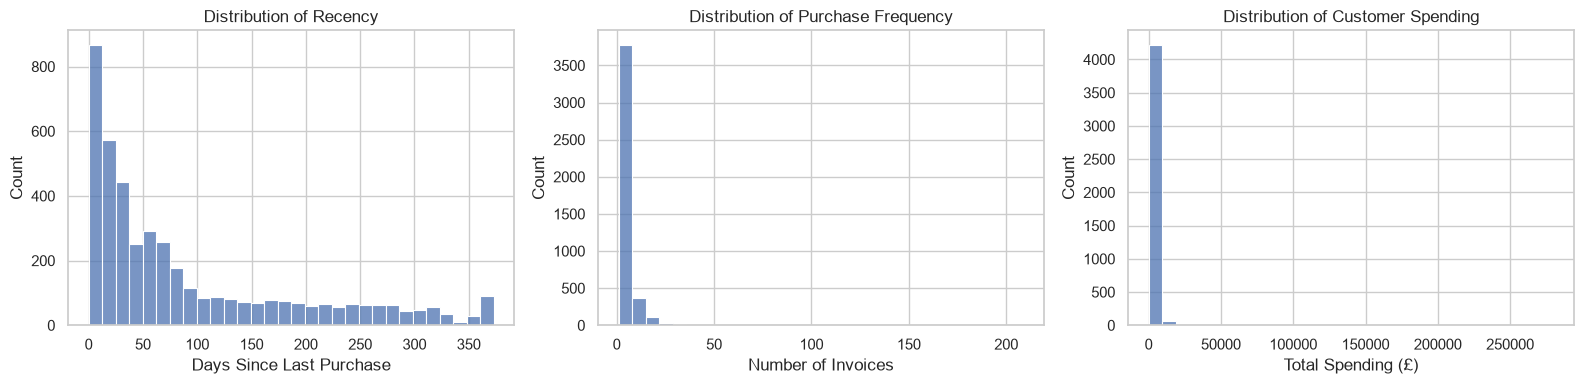

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(rfm["Recency"], bins=30, ax=axes[0])
axes[0].set_title("Distribution of Recency")
axes[0].set_xlabel("Days Since Last Purchase")

sns.histplot(rfm["Frequency"], bins=30, ax=axes[1])
axes[1].set_title("Distribution of Purchase Frequency")
axes[1].set_xlabel("Number of Invoices")

sns.histplot(rfm["Monetary"], bins=30, ax=axes[2])
axes[2].set_title("Distribution of Customer Spending")
axes[2].set_xlabel("Total Spending (£)")

plt.tight_layout()
plt.savefig("../images/rfm_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Feature Standardization

In [30]:
features = ["Recency", "Frequency", "Monetary"]

X = rfm[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original feature means:")
display(X.mean().round(2))

print("\nStandardized feature means:")
print(X_scaled.mean(axis=0).round(4))

print("\nStandardized feature standard deviations:")
print(X_scaled.std(axis=0).round(4))

Original feature means:


Recency        92.06
Frequency       4.27
Monetary     2054.27
dtype: float64


Standardized feature means:
[-0.  0.  0.]

Standardized feature standard deviations:
[1. 1. 1.]


### Standardization Observation

The RFM features use different units and scales. StandardScaler transforms the features to comparable scales, helping prevent a feature with larger numerical values from dominating K-Means distance calculations.

## 6. Determine the Number of Clusters

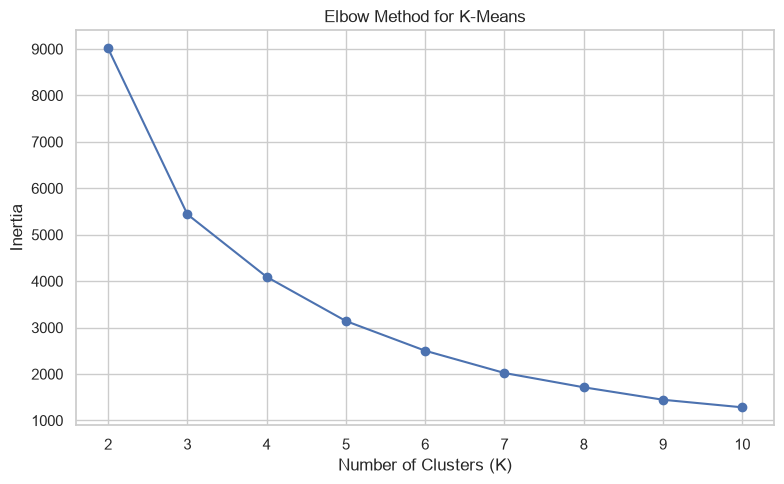

In [31]:
inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig("../images/elbow_method.png", dpi=300, bbox_inches="tight")
plt.show()

In [32]:
silhouette_results = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)

    silhouette_results.append({
        "K": k,
        "Silhouette Score": silhouette_score(X_scaled, labels)
    })

silhouette_df = pd.DataFrame(silhouette_results)
display(silhouette_df.round(3))

,K,Silhouette Score
0,2,0.896
1,3,0.594
2,4,0.616
3,5,0.617
4,6,0.587


In [33]:
best_k = 4  # Change this if your Elbow Method suggests another K

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)

print("Selected number of clusters:", best_k)
display(rfm.head())

Selected number of clusters: 4


,CustomerID,Recency,Frequency,Monetary,Avg_Purchase_Value,Cluster
0,12346,325,1,77183.60,77183.600000,3
1,12347,2,7,4310.00,615.714286,0
2,12348,75,4,1797.24,449.310000,0
3,12349,18,1,1757.55,1757.550000,0
4,12350,310,1,334.40,334.400000,1


### K-Means Observation

K-Means assigns each customer to one of the selected clusters based on the standardized RFM features. The cluster numbers are identifiers, not rankings: Cluster 0 is not automatically better than Cluster 1.

## 7. Customer Segment Visualizations

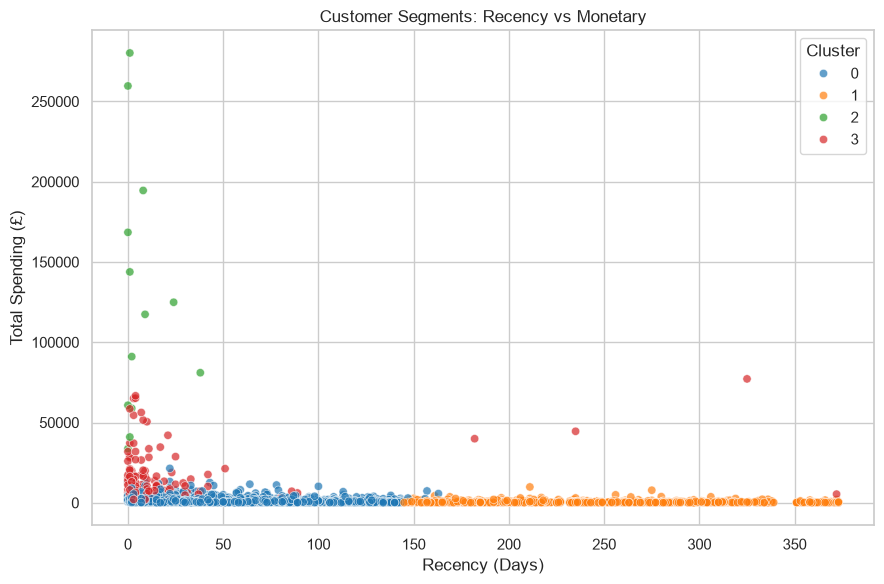

In [34]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("Customer Segments: Recency vs Monetary")
plt.xlabel("Recency (Days)")
plt.ylabel("Total Spending (£)")
plt.tight_layout()
plt.savefig("../images/recency_vs_monetary.png", dpi=300, bbox_inches="tight")
plt.show()

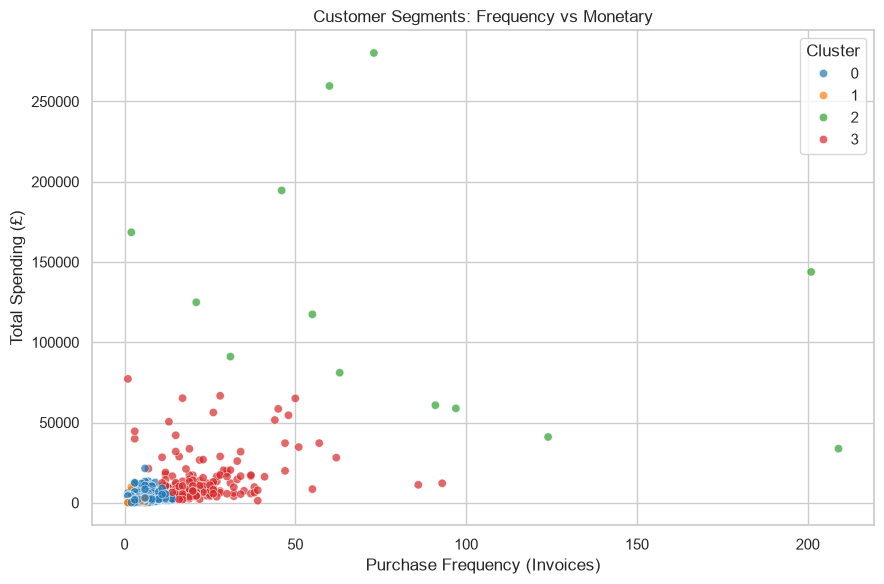

In [35]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("Customer Segments: Frequency vs Monetary")
plt.xlabel("Purchase Frequency (Invoices)")
plt.ylabel("Total Spending (£)")
plt.tight_layout()
plt.savefig("../images/frequency_vs_monetary.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Cluster Profiles

In [36]:
cluster_profile = rfm.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median")
).round(2)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"]
    / len(rfm) * 100
).round(2)

display(cluster_profile)

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary,Customer_Percentage
Cluster,,,,,,
0,3060,43.43,3.68,1358.17,826.81,70.54
1,1061,248.17,1.55,478.19,309.80,24.46
2,13,6.62,82.54,127338.31,117379.63,0.30
3,204,14.96,22.33,12709.09,8037.73,4.70


## 9. Customer Count by Cluster

,Cluster,Number of Customers
0,0,3060
1,1,1061
2,2,13
3,3,204


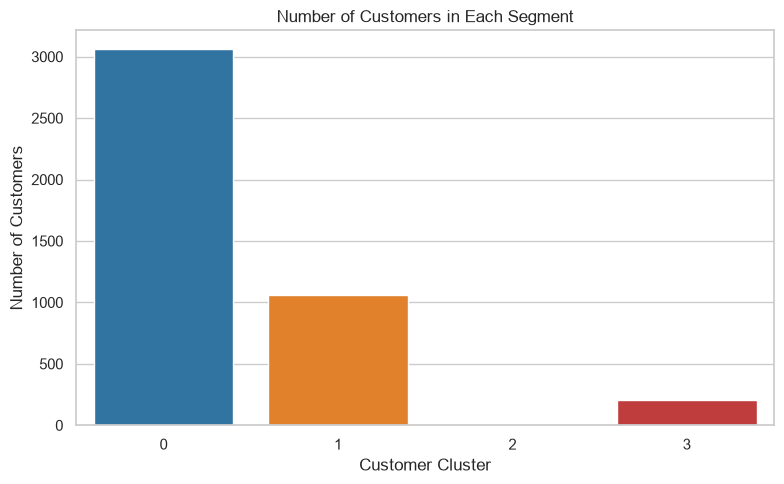

In [37]:
cluster_counts = (
    rfm["Cluster"]
    .value_counts()
    .sort_index()
    .reset_index()
)

cluster_counts.columns = ["Cluster", "Number of Customers"]

display(cluster_counts)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=cluster_counts,
    x="Cluster",
    y="Number of Customers",
    hue="Cluster",
    palette="tab10",
    legend=False
)

plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("../images/customers_per_cluster.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Customer Segment Insights and Marketing Recommendations

In [38]:
display(
    cluster_profile[
        [
            "Customer_Count",
            "Customer_Percentage",
            "Avg_Recency",
            "Avg_Frequency",
            "Avg_Monetary"
        ]
    ]
)

,Customer_Count,Customer_Percentage,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,,
0,3060,70.54,43.43,3.68,1358.17
1,1061,24.46,248.17,1.55,478.19
2,13,0.30,6.62,82.54,127338.31
3,204,4.70,14.96,22.33,12709.09


## 11. Conclusion

This project applied K-Means clustering to segment customers from an online retail dataset using Recency, Frequency, and Monetary (RFM) analysis.

The original dataset contained 541,909 transaction records. After data cleaning, 397,884 records representing 4,338 unique customers remained. The RFM features were standardized before clustering, and the Elbow Method and silhouette scores were examined to help evaluate the clustering results.

Using four clusters, the analysis identified distinct purchasing patterns. Cluster 0 was the largest segment, containing 70.54% of customers, who showed moderate purchasing activity and spending. Cluster 1 contained 24.46% of customers and had the highest average recency, indicating that these customers had not purchased recently and could be suitable targets for re-engagement campaigns.

Cluster 2 represented a small group of 13 exceptionally high-value customers, with the highest average purchase frequency and spending. Cluster 3 contained 204 relatively frequent, high-spending customers who had also purchased recently. These groups could be targeted with personalized loyalty rewards, retention campaigns, and relevant product recommendations.

Overall, the analysis demonstrates how customer segmentation can help a retailer understand different purchasing behaviours and develop more targeted marketing strategies. The results also highlight the importance of evaluating cluster sizes and customer characteristics when interpreting K-Means output.